In [1]:
from pathlib import Path
import gzip
import struct
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns



sns.set_theme(style="whitegrid")

# Tìm thư mục khi chạy notebook từ workspace hoặc thư mục bài tập.
assignment_dir = "Ex-03_Nguyen_Hoang_Phuc_CNTT59C"
expected_names = {
    "train-images-idx3-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz",
}
dataset_root = None
for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    candidates = [
        base / assignment_dir / "MNIST_datasets",
        base / assignment_dir / "MNIST_hand_drawn_datasets",
        base / "MNIST_datasets",
        base / "MNIST_hand_drawn_datasets",
        base / "data" / "raw" / "MNIST_hand_drawn",
    ]
    for candidate in candidates:
        if candidate.is_dir() and expected_names.issubset(
            {path.name for path in candidate.rglob("*.gz")}
        ):
            dataset_root = candidate
            break
    if dataset_root is not None:
        break

if dataset_root is None:
    raise FileNotFoundError(
        "Không tìm thấy đủ bốn tệp MNIST IDX .gz. Hãy đặt dữ liệu trong "
        "MNIST_datasets hoặc MNIST_hand_drawn_datasets."
    )

dataset_files = {
    path.name: path for path in dataset_root.rglob("*.gz")
    if path.name in expected_names
}

def load_idx_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        if magic != 2051:
            raise ValueError(f"Sai mã IDX ảnh trong {path}: {magic}")
        images = np.frombuffer(file.read(), dtype=np.uint8)
    if images.size != count * rows * cols:
        raise ValueError(f"Kích thước dữ liệu ảnh không hợp lệ: {path}")
    return images.reshape(count, rows, cols)

def load_idx_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        if magic != 2049:
            raise ValueError(f"Sai mã IDX nhãn trong {path}: {magic}")
        labels = np.frombuffer(file.read(), dtype=np.uint8)
    if labels.size != count:
        raise ValueError(f"Số lượng nhãn không khớp: {path}")
    return labels

X_train_raw = load_idx_images(dataset_files["train-images-idx3-ubyte.gz"])
y_train_raw = load_idx_labels(dataset_files["train-labels-idx1-ubyte.gz"])
X_test_raw = load_idx_images(dataset_files["t10k-images-idx3-ubyte.gz"])
y_test_raw = load_idx_labels(dataset_files["t10k-labels-idx1-ubyte.gz"])

print(f"Thư mục dữ liệu: {dataset_root}")
print(f"Train: ảnh {X_train_raw.shape}, nhãn {y_train_raw.shape}")
print(f"Test : ảnh {X_test_raw.shape}, nhãn {y_test_raw.shape}")


Thư mục dữ liệu: /workspaces/LEARNING-ML/Ex-03_Nguyen_Hoang_Phuc_CNTT59C/MNIST_hand_drawn_datasets
Train: ảnh (60000, 28, 28), nhãn (60000,)
Test : ảnh (10000, 28, 28), nhãn (10000,)


,Tập dữ liệu,Số ảnh,Kích thước ảnh,Kiểu pixel,Pixel nhỏ nhất,Pixel lớn nhất,Số nhãn khác nhau
0,Train,60000,28 × 28,uint8,0,255,10
1,Test,10000,28 × 28,uint8,0,255,10


Nhãn trong train: [0 1 2 3 4 5 6 7 8 9]
Giá trị thiếu trong ảnh/nhãn: 0 / 0
Số mẫu train và nhãn không khớp: 0


,Train,Test
Chữ số,,
0,5923,980
1,6742,1135
2,5958,1032
3,6131,1010
4,5842,982
5,5421,892
6,5918,958
7,6265,1028
8,5851,974


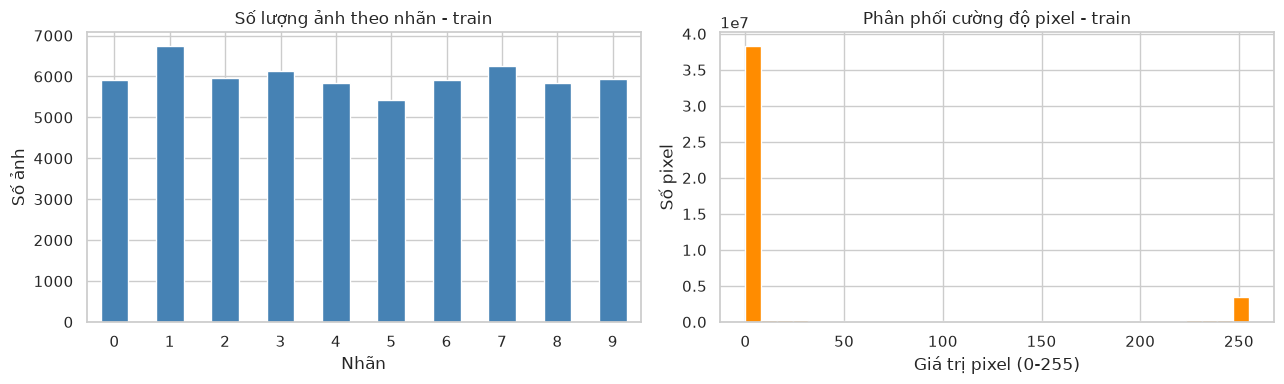

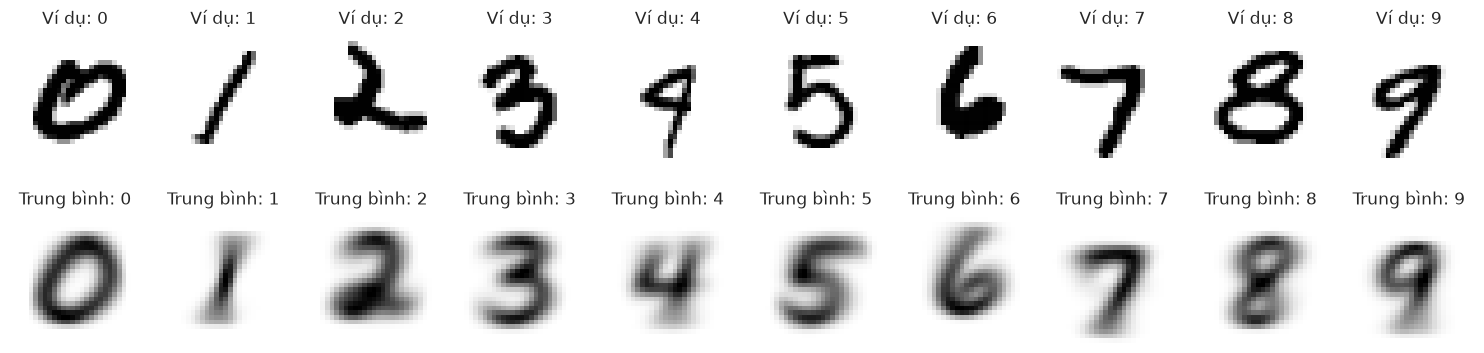

In [2]:
overview = pd.DataFrame([
    {
        "Tập dữ liệu": name,
        "Số ảnh": len(images),
        "Kích thước ảnh": f"{images.shape[1]} × {images.shape[2]}",
        "Kiểu pixel": str(images.dtype),
        "Pixel nhỏ nhất": int(images.min()),
        "Pixel lớn nhất": int(images.max()),
        "Số nhãn khác nhau": np.unique(labels).size,
    }
    for name, images, labels in [
        ("Train", X_train_raw, y_train_raw),
        ("Test", X_test_raw, y_test_raw),
    ]
])
display(overview)
print("Nhãn trong train:", np.unique(y_train_raw))
print("Giá trị thiếu trong ảnh/nhãn:", np.isnan(X_train_raw).sum(), "/", np.isnan(y_train_raw).sum())
print("Số mẫu train và nhãn không khớp:", len(X_train_raw) - len(y_train_raw))

train_counts = pd.Series(y_train_raw).value_counts().sort_index()
test_counts = pd.Series(y_test_raw).value_counts().sort_index()
display(pd.DataFrame({"Train": train_counts, "Test": test_counts}).rename_axis("Chữ số"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_counts.plot(kind="bar", ax=axes[0], color="steelblue", title="Số lượng ảnh theo nhãn - train")
axes[0].set(xlabel="Nhãn", ylabel="Số ảnh")
axes[0].tick_params(axis="x", rotation=0)
axes[1].hist(X_train_raw.ravel(), bins=32, color="darkorange", edgecolor="white")
axes[1].set(title="Phân phối cường độ pixel - train", xlabel="Giá trị pixel (0-255)", ylabel="Số pixel")
plt.tight_layout()
plt.show()

# Mỗi cột là một chữ số: một ảnh ví dụ và ảnh trung bình theo lớp.
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
rng = np.random.default_rng(42)
for digit in range(10):
    example_index = rng.choice(np.flatnonzero(y_train_raw == digit))
    axes[0, digit].imshow(X_train_raw[example_index], cmap="gray_r")
    axes[0, digit].set_title(f"Ví dụ: {digit}")
    axes[1, digit].imshow(X_train_raw[y_train_raw == digit].mean(axis=0), cmap="gray_r")
    axes[1, digit].set_title(f"Trung bình: {digit}")
    axes[0, digit].axis("off")
    axes[1, digit].axis("off")
plt.tight_layout()
plt.show()


## Bài 3 — Phân loại chữ số viết tay MNIST

Cài đặt từ đầu bằng NumPy: hồi quy Softmax, Gaussian Naive Bayes, k-NN, cây quyết định theo Gini, SVM tuyến tính, SVM kernel RBF và MLP (sáu họ mô hình; SVM có hai kernel để đối chiếu). Không dùng estimator scikit-learn.

Dữ liệu train/test giữ nguyên hai phần chính thức MNIST (60.000/10.000 ảnh), được làm phẳng thành 784 đặc trưng và chuẩn hóa về [0, 1]. Tuning chọn tham số trên holdout phân tầng từ train. SVM RBF được fit trên mẫu train phân tầng 1.500 ảnh để giới hạn ma trận kernel bậc hai; số mẫu thực tế được báo cáo cùng kết quả, vì vậy cần lưu ý khi so sánh công bằng với các mô hình dùng đủ 60.000 ảnh.

Bảng kết quả gồm Accuracy, Precision/Recall macro, Macro F1, thời gian train, thời gian dự đoán toàn test và độ trễ trung bình mỗi ảnh; các phần sau hiển thị biểu đồ, confusion matrix và ví dụ phân loại sai.

In [3]:
RANDOM_STATE = 42
TRAIN_SAMPLES = len(y_train_raw)
RBF_TRAIN_SAMPLES = 1_500
N_CLASSES = 10
rng = np.random.default_rng(RANDOM_STATE)


def stratified_sample_indices(labels, sample_size, random_generator):
    labels = np.asarray(labels)
    if sample_size > len(labels):
        raise ValueError("Kích thước mẫu vượt quá số lượng dữ liệu.")
    classes, counts = np.unique(labels, return_counts=True)
    exact_counts = counts * (sample_size / len(labels))
    sample_counts = np.floor(exact_counts).astype(int)
    remainder = sample_size - sample_counts.sum()
    if remainder:
        order = np.argsort(-(exact_counts - sample_counts))
        sample_counts[order[:remainder]] += 1
    selected = []
    for label, count in zip(classes, sample_counts):
        candidates = np.flatnonzero(labels == label)
        selected.extend(random_generator.choice(candidates, size=count, replace=False))
    selected = np.asarray(selected, dtype=int)
    random_generator.shuffle(selected)
    return selected


train_indices = np.arange(TRAIN_SAMPLES)
X_train = X_train_raw[train_indices].reshape(TRAIN_SAMPLES, -1).astype(np.float32) / 255.0
y_train = y_train_raw[train_indices].astype(np.int64)
X_test = X_test_raw.reshape(len(X_test_raw), -1).astype(np.float32) / 255.0
y_test = y_test_raw.astype(np.int64)
print(f"Train phân tầng: {X_train.shape}; test chính thức: {X_test.shape}")

tune_indices = stratified_sample_indices(y_train, 2_000, rng)
X_tune_all, y_tune_all = X_train[tune_indices], y_train[tune_indices]
validation_indices = stratified_sample_indices(y_tune_all, 500, rng)
is_validation = np.zeros(len(y_tune_all), dtype=bool)
is_validation[validation_indices] = True
X_tune, y_tune = X_tune_all[~is_validation], y_tune_all[~is_validation]
X_validation, y_validation = X_tune_all[is_validation], y_tune_all[is_validation]


def confusion_matrix_numpy(y_true, y_pred, class_count=N_CLASSES):
    matrix = np.zeros((class_count, class_count), dtype=np.int64)
    np.add.at(matrix, (y_true, y_pred), 1)
    return matrix


def classification_metrics(y_true, y_pred):
    matrix = confusion_matrix_numpy(y_true, y_pred)
    true_positive = np.diag(matrix).astype(float)
    precision = np.divide(
        true_positive, matrix.sum(axis=0),
        out=np.zeros_like(true_positive), where=matrix.sum(axis=0) != 0,
    )
    recall = np.divide(
        true_positive, matrix.sum(axis=1),
        out=np.zeros_like(true_positive), where=matrix.sum(axis=1) != 0,
    )
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros_like(precision), where=(precision + recall) != 0,
    )
    return {
        "Accuracy": float(true_positive.sum() / matrix.sum()),
        "Precision (macro)": float(precision.mean()),
        "Recall (macro)": float(recall.mean()),
        "Macro F1": float(f1.mean()),
    }


class SoftmaxRegression:
    def __init__(self, regularization=1e-4, learning_rate=0.5, epochs=12):
        self.regularization = regularization
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        random_generator = np.random.default_rng(RANDOM_STATE)
        self.weights = np.zeros((X.shape[1], N_CLASSES), dtype=np.float32)
        self.bias = np.zeros(N_CLASSES, dtype=np.float32)
        targets = np.eye(N_CLASSES, dtype=np.float32)[y]
        for _ in range(self.epochs):
            order = random_generator.permutation(len(X))
            for start in range(0, len(X), 256):
                indices = order[start:start + 256]
                batch = X[indices]
                logits = batch @ self.weights + self.bias
                logits -= logits.max(axis=1, keepdims=True)
                probabilities = np.exp(logits)
                probabilities /= probabilities.sum(axis=1, keepdims=True)
                error = probabilities - targets[indices]
                self.weights -= self.learning_rate * (
                    batch.T @ error / len(indices) + self.regularization * self.weights
                )
                self.bias -= self.learning_rate * error.mean(axis=0)
        return self

    def predict(self, X):
        return np.argmax(X @ self.weights + self.bias, axis=1)


class GaussianNaiveBayes:
    def fit(self, X, y):
        self.log_prior = np.zeros(N_CLASSES, dtype=np.float64)
        self.means = np.zeros((N_CLASSES, X.shape[1]), dtype=np.float32)
        self.variances = np.zeros_like(self.means)
        for label in range(N_CLASSES):
            class_samples = X[y == label]
            self.log_prior[label] = np.log(len(class_samples) / len(X))
            self.means[label] = class_samples.mean(axis=0)
            self.variances[label] = class_samples.var(axis=0) + 1e-3
        return self

    def predict(self, X):
        scores = np.empty((len(X), N_CLASSES), dtype=np.float64)
        for label in range(N_CLASSES):
            variance = self.variances[label]
            scores[:, label] = self.log_prior[label] - 0.5 * np.sum(
                np.log(2 * np.pi * variance)
                + (X - self.means[label]) ** 2 / variance,
                axis=1,
            )
        return np.argmax(scores, axis=1)


class KNearestNeighbors:
    def __init__(self, neighbors=5, metric="euclidean", batch_size=128):
        self.neighbors = neighbors
        self.metric = metric
        self.batch_size = batch_size

    def fit(self, X, y):
        self.X = X
        self.y = y
        self.squared_norms = np.sum(X * X, axis=1)
        return self

    def predict(self, X):
        predictions = np.empty(len(X), dtype=np.int64)
        for start in range(0, len(X), self.batch_size):
            batch = X[start:start + self.batch_size]
            if self.metric == "euclidean":
                distances = (
                    np.sum(batch * batch, axis=1)[:, None]
                    + self.squared_norms[None, :]
                    - 2 * batch @ self.X.T
                )
                np.maximum(distances, 0, out=distances)
            else:
                distances = np.empty((len(batch), len(self.X)), dtype=np.float32)
                for row_start in range(0, len(batch), 8):
                    rows = batch[row_start:row_start + 8]
                    distances[row_start:row_start + len(rows)] = np.abs(
                        rows[:, None, :] - self.X[None, :, :]
                    ).sum(axis=2)
            nearest = np.argpartition(
                distances, self.neighbors - 1, axis=1
            )[:, :self.neighbors]
            for row, neighbor_indices in enumerate(nearest):
                predictions[start + row] = np.bincount(
                    self.y[neighbor_indices], minlength=N_CLASSES
                ).argmax()
        return predictions


class DecisionTree:
    def __init__(self, max_depth=10, max_features=48, min_leaf=20):
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_leaf = min_leaf
        self.random_generator = np.random.default_rng(RANDOM_STATE)

    def _best_split(self, X, y, indices):
        feature_count = min(self.max_features, X.shape[1])
        features = self.random_generator.choice(X.shape[1], feature_count, replace=False)
        one_hot = np.eye(N_CLASSES, dtype=np.int32)[y[indices]]
        best_gain, best_split = 0.0, None
        parent_counts = one_hot.sum(axis=0)
        parent_impurity = 1.0 - np.sum((parent_counts / len(indices)) ** 2)
        for feature in features:
            values = X[indices, feature]
            order = np.argsort(values)
            sorted_values = values[order]
            boundaries = np.flatnonzero(sorted_values[:-1] < sorted_values[1:])
            boundaries = boundaries[
                (boundaries + 1 >= self.min_leaf)
                & (len(indices) - boundaries - 1 >= self.min_leaf)
            ]
            if not len(boundaries):
                continue
            cumulative = np.cumsum(one_hot[order], axis=0)
            left_counts = cumulative[boundaries]
            right_counts = parent_counts - left_counts
            left_size = boundaries + 1
            right_size = len(indices) - left_size
            impurity = (
                left_size * (1 - np.sum(left_counts ** 2, axis=1) / left_size ** 2)
                + right_size * (1 - np.sum(right_counts ** 2, axis=1) / right_size ** 2)
            ) / len(indices)
            gains = parent_impurity - impurity
            position = int(np.argmax(gains))
            if gains[position] > best_gain:
                split_index = boundaries[position]
                threshold = (sorted_values[split_index] + sorted_values[split_index + 1]) / 2
                best_gain = float(gains[position])
                best_split = (int(feature), float(threshold))
        return best_split

    def fit(self, X, y):
        def grow(indices, depth):
            labels = y[indices]
            counts = np.bincount(labels, minlength=N_CLASSES)
            node = {"prediction": int(counts.argmax())}
            if depth >= self.max_depth or len(indices) < 2 * self.min_leaf or np.count_nonzero(counts) == 1:
                return node
            split = self._best_split(X, y, indices)
            if split is None:
                return node
            feature, threshold = split
            left_mask = X[indices, feature] <= threshold
            if left_mask.all() or not left_mask.any():
                return node
            node.update({
                "feature": feature,
                "threshold": threshold,
                "left": grow(indices[left_mask], depth + 1),
                "right": grow(indices[~left_mask], depth + 1),
            })
            return node

        self.root = grow(np.arange(len(X)), 0)
        return self

    def predict(self, X):
        predictions = np.empty(len(X), dtype=np.int64)

        def assign(node, row_indices):
            if not len(row_indices):
                return
            if "feature" not in node:
                predictions[row_indices] = node["prediction"]
                return
            left_mask = X[row_indices, node["feature"]] <= node["threshold"]
            assign(node["left"], row_indices[left_mask])
            assign(node["right"], row_indices[~left_mask])

        assign(self.root, np.arange(len(X)))
        return predictions


class LinearSVM:
    def __init__(self, C=1.0, learning_rate=0.02, epochs=12):
        self.C = C
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        random_generator = np.random.default_rng(RANDOM_STATE)
        self.weights = np.zeros((X.shape[1], N_CLASSES), dtype=np.float32)
        self.bias = np.zeros(N_CLASSES, dtype=np.float32)
        for _ in range(self.epochs):
            order = random_generator.permutation(len(X))
            for start in range(0, len(X), 256):
                indices = order[start:start + 256]
                batch = X[indices]
                targets = -np.ones((len(indices), N_CLASSES), dtype=np.float32)
                targets[np.arange(len(indices)), y[indices]] = 1
                margins = 1 - targets * (batch @ self.weights + self.bias)
                active = (margins > 0).astype(np.float32)
                direction = targets * active
                self.weights -= self.learning_rate * (
                    self.weights - self.C * (batch.T @ direction) / len(indices)
                )
                self.bias += self.learning_rate * self.C * direction.mean(axis=0)
        return self

    def predict(self, X):
        return np.argmax(X @ self.weights + self.bias, axis=1)


def rbf_kernel(X_left, X_right, gamma):
    squared_left = np.sum(X_left * X_left, axis=1)[:, None]
    squared_right = np.sum(X_right * X_right, axis=1)[None, :]
    distances = squared_left + squared_right - 2 * X_left @ X_right.T
    np.maximum(distances, 0, out=distances)
    return np.exp(-gamma * distances).astype(np.float32)


class RbfKernelSVM:
    def __init__(self, C=1.0, gamma=0.03, iterations=50, learning_rate=0.01):
        self.C = C
        self.gamma = gamma
        self.iterations = iterations
        self.learning_rate = learning_rate

    def fit(self, X, y):
        self.X = X
        kernel = rbf_kernel(X, X, self.gamma)
        targets = -np.ones((len(X), N_CLASSES), dtype=np.float32)
        targets[np.arange(len(X)), y] = 1
        self.coefficients = np.zeros_like(targets)
        self.bias = np.zeros(N_CLASSES, dtype=np.float32)
        first_moment = np.zeros_like(self.coefficients)
        second_moment = np.zeros_like(self.coefficients)
        for iteration in range(1, self.iterations + 1):
            scores = kernel @ self.coefficients + self.bias
            margins = np.maximum(1 - targets * scores, 0)
            gradient = (
                kernel @ self.coefficients
                - self.C * kernel @ (targets * margins)
            ) / len(X)
            bias_gradient = -self.C * np.mean(targets * margins, axis=0)
            first_moment = 0.9 * first_moment + 0.1 * gradient
            second_moment = 0.999 * second_moment + 0.001 * gradient ** 2
            corrected_first = first_moment / (1 - 0.9 ** iteration)
            corrected_second = second_moment / (1 - 0.999 ** iteration)
            self.coefficients -= self.learning_rate * corrected_first / (
                np.sqrt(corrected_second) + 1e-8
            )
            self.bias -= self.learning_rate * bias_gradient
        return self

    def predict(self, X):
        return np.argmax(rbf_kernel(X, self.X, self.gamma) @ self.coefficients + self.bias, axis=1)


class MlpClassifier:
    def __init__(self, hidden_units=64, learning_rate=0.001, epochs=12):
        self.hidden_units = hidden_units
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        random_generator = np.random.default_rng(RANDOM_STATE)
        input_scale = np.sqrt(2 / X.shape[1])
        hidden_scale = np.sqrt(2 / self.hidden_units)
        self.W1 = random_generator.normal(
            0, input_scale, (X.shape[1], self.hidden_units)
        ).astype(np.float32)
        self.b1 = np.zeros(self.hidden_units, dtype=np.float32)
        self.W2 = random_generator.normal(
            0, hidden_scale, (self.hidden_units, N_CLASSES)
        ).astype(np.float32)
        self.b2 = np.zeros(N_CLASSES, dtype=np.float32)
        parameters = [self.W1, self.b1, self.W2, self.b2]
        first_moments = [np.zeros_like(value) for value in parameters]
        second_moments = [np.zeros_like(value) for value in parameters]
        targets = np.eye(N_CLASSES, dtype=np.float32)[y]
        step = 0
        for _ in range(self.epochs):
            order = random_generator.permutation(len(X))
            for start in range(0, len(X), 128):
                step += 1
                indices = order[start:start + 128]
                batch = X[indices]
                hidden_linear = batch @ self.W1 + self.b1
                hidden = np.maximum(hidden_linear, 0)
                logits = hidden @ self.W2 + self.b2
                logits -= logits.max(axis=1, keepdims=True)
                probabilities = np.exp(logits)
                probabilities /= probabilities.sum(axis=1, keepdims=True)
                output_error = (probabilities - targets[indices]) / len(indices)
                grad_W2 = hidden.T @ output_error
                grad_b2 = output_error.sum(axis=0)
                hidden_error = (output_error @ self.W2.T) * (hidden_linear > 0)
                gradients = [
                    batch.T @ hidden_error, hidden_error.sum(axis=0),
                    grad_W2, grad_b2,
                ]
                for i, (parameter, gradient) in enumerate(zip(parameters, gradients)):
                    first_moments[i] = 0.9 * first_moments[i] + 0.1 * gradient
                    second_moments[i] = 0.999 * second_moments[i] + 0.001 * gradient ** 2
                    corrected_first = first_moments[i] / (1 - 0.9 ** step)
                    corrected_second = second_moments[i] / (1 - 0.999 ** step)
                    parameter -= self.learning_rate * corrected_first / (
                        np.sqrt(corrected_second) + 1e-8
                    )
        return self

    def predict(self, X):
        return np.argmax(np.maximum(X @ self.W1 + self.b1, 0) @ self.W2 + self.b2, axis=1)


def tune_model(name, candidates, factory, fit_X=X_tune, fit_y=y_tune):
    records = []
    best_score, best_parameters = -1.0, None
    for parameters in candidates:
        model = factory(**parameters)
        model.fit(fit_X, fit_y)
        score = classification_metrics(y_validation, model.predict(X_validation))["Macro F1"]
        records.append({
            "Mô hình": name,
            "Tham số": ", ".join(f"{key}={value}" for key, value in parameters.items()),
            "Macro F1 validation": score,
        })
        if score > best_score:
            best_score, best_parameters = score, parameters
    return best_parameters, records


tuning_records = []
selected_parameters = {}
selected_parameters["Logistic Regression"], records = tune_model(
    "Logistic Regression",
    [{"regularization": value, "epochs": 8} for value in (1e-4, 1e-3)],
    SoftmaxRegression,
)
tuning_records.extend(records)

knn_candidates = [
    {"neighbors": neighbors, "metric": metric}
    for metric in ("euclidean", "manhattan")
    for neighbors in (3, 5, 7)
]
selected_parameters["k-NN"], records = tune_model(
    "k-NN", knn_candidates, KNearestNeighbors
)
tuning_records.extend(records)

selected_parameters["Decision Tree"], records = tune_model(
    "Decision Tree",
    [{"max_depth": depth} for depth in (8, 12)],
    DecisionTree,
)
tuning_records.extend(records)

selected_parameters["SVM tuyến tính"], records = tune_model(
    "SVM tuyến tính",
    [{"C": value, "epochs": 32} for value in (0.1, 1.0, 5.0, 10.0)],
    LinearSVM,
)
tuning_records.extend(records)

rbf_fit_indices = stratified_sample_indices(y_tune, 800, rng)
rbf_tune_X, rbf_tune_y = X_tune[rbf_fit_indices], y_tune[rbf_fit_indices]
rbf_validation_indices = stratified_sample_indices(y_validation, 300, rng)
X_rbf_validation, y_rbf_validation = (
    X_validation[rbf_validation_indices], y_validation[rbf_validation_indices]
)
rbf_tuning_records = []
best_rbf_score, best_rbf_parameters = -1.0, None
for gamma in (0.01, 0.03, 0.05):
    for C in (0.5, 1.0, 5.0):
        candidate = RbfKernelSVM(C=C, gamma=gamma, iterations=100)
        candidate.fit(rbf_tune_X, rbf_tune_y)
        score = classification_metrics(
            y_rbf_validation, candidate.predict(X_rbf_validation)
        )["Macro F1"]
        rbf_tuning_records.append({
            "Mô hình": "SVM RBF", "Tham số": f"C={C}, gamma={gamma}",
            "Macro F1 validation": score,
        })
        if score > best_rbf_score:
            best_rbf_score = score
            best_rbf_parameters = {"C": C, "gamma": gamma}
tuning_records.extend(rbf_tuning_records)
selected_parameters["SVM RBF"] = best_rbf_parameters

selected_parameters["MLP"], records = tune_model(
    "MLP",
    [{"learning_rate": value, "epochs": 6} for value in (0.001, 0.003)],
    MlpClassifier,
)
tuning_records.extend(records)
tuning_results = pd.DataFrame(tuning_records).sort_values(
    ["Mô hình", "Macro F1 validation"], ascending=[True, False]
).reset_index(drop=True)
display(tuning_results.round(4))

selected_parameters["Gaussian Naive Bayes"] = {}
for model_name in ("Logistic Regression", "SVM tuyến tính", "MLP"):
    selected_parameters[model_name] = {
        key: value for key, value in selected_parameters[model_name].items()
        if key != "epochs"
    }

models = {
    "Logistic Regression": SoftmaxRegression(
        **selected_parameters["Logistic Regression"], epochs=16
    ),
    "Gaussian Naive Bayes": GaussianNaiveBayes(),
    "k-NN": KNearestNeighbors(**selected_parameters["k-NN"]),
    "Decision Tree": DecisionTree(**selected_parameters["Decision Tree"]),
    "SVM tuyến tính": LinearSVM(
        **selected_parameters["SVM tuyến tính"], epochs=40
    ),
    "SVM RBF": RbfKernelSVM(
        **selected_parameters["SVM RBF"], iterations=150
    ),
    "MLP": MlpClassifier(
        **selected_parameters["MLP"], epochs=16
    ),
}

fitted_models = {}
predictions = {}
results = []
for name, model in models.items():
    model_train_X, model_train_y = X_train, y_train
    if name == "SVM RBF":
        rbf_indices = stratified_sample_indices(y_train, RBF_TRAIN_SAMPLES, rng)
        model_train_X, model_train_y = X_train[rbf_indices], y_train[rbf_indices]
    start = time.perf_counter()
    model.fit(model_train_X, model_train_y)
    training_seconds = time.perf_counter() - start
    start = time.perf_counter()
    predictions[name] = model.predict(X_test)
    test_seconds = time.perf_counter() - start
    fitted_models[name] = model
    results.append({
        "Mô hình": name,
        **classification_metrics(y_test, predictions[name]),
        "Training time (s)": training_seconds,
        "Test latency (s)": test_seconds,
        "Latency (ms/ảnh)": test_seconds * 1000 / len(X_test),
        "Số mẫu train": len(model_train_y),
        "Hyperparameters": str(selected_parameters[name]),
    })
    print(
        f"{name}: accuracy={results[-1]['Accuracy']:.4f}, "
        f"macro-F1={results[-1]['Macro F1']:.4f}, "
        f"train={training_seconds:.1f}s, "
        f"test={test_seconds:.1f}s"
    )

results_df = pd.DataFrame(results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)
display(results_df.round({
    "Accuracy": 4,
    "Precision (macro)": 4,
    "Recall (macro)": 4,
    "Macro F1": 4,
    "Training time (s)": 2,
    "Test latency (s)": 2,
    "Latency (ms/ảnh)": 3,
}))


Train phân tầng: (60000, 784); test chính thức: (10000, 784)


,Mô hình,Tham số,Macro F1 validation
0,Decision Tree,max_depth=8,0.6122
1,Decision Tree,max_depth=12,0.5985
2,Logistic Regression,"regularization=0.0001, epochs=8",0.8768
3,Logistic Regression,"regularization=0.001, epochs=8",0.8768
4,MLP,"learning_rate=0.003, epochs=6",0.8821
5,MLP,"learning_rate=0.001, epochs=6",0.8679
6,SVM RBF,"C=1.0, gamma=0.05",0.8918
7,SVM RBF,"C=5.0, gamma=0.05",0.8888
8,SVM RBF,"C=0.5, gamma=0.05",0.8887
9,SVM RBF,"C=5.0, gamma=0.03",0.8678


Logistic Regression: accuracy=0.9241, macro-F1=0.9233, train=2.1s, test=0.0s


Gaussian Naive Bayes: accuracy=0.7746, macro-F1=0.7711, train=0.1s, test=0.2s


k-NN: accuracy=0.9705, macro-F1=0.9704, train=0.1s, test=16.2s


Decision Tree: accuracy=0.7619, macro-F1=0.7588, train=2.5s, test=0.0s


SVM tuyến tính: accuracy=0.8571, macro-F1=0.8528, train=4.4s, test=0.0s


SVM RBF: accuracy=0.9303, macro-F1=0.9294, train=0.6s, test=0.4s


MLP: accuracy=0.9759, macro-F1=0.9757, train=6.6s, test=0.0s


,Mô hình,Accuracy,Precision (macro),Recall (macro),Macro F1,Training time (s),Test latency (s),Latency (ms/ảnh),Số mẫu train,Hyperparameters
0,MLP,0.9759,0.9759,0.9756,0.9757,6.64,0.01,0.001,60000,{'learning_rate': 0.003}
1,k-NN,0.9705,0.9709,0.9701,0.9704,0.06,16.23,1.623,60000,"{'neighbors': 3, 'metric': 'euclidean'}"
2,SVM RBF,0.9303,0.9300,0.9295,0.9294,0.64,0.36,0.036,1500,"{'C': 1.0, 'gamma': 0.05}"
3,Logistic Regression,0.9241,0.9237,0.9233,0.9233,2.08,0.01,0.001,60000,{'regularization': 0.0001}
4,SVM tuyến tính,0.8571,0.8630,0.8546,0.8528,4.44,0.01,0.001,60000,{'C': 10.0}
5,Gaussian Naive Bayes,0.7746,0.8008,0.7701,0.7711,0.11,0.21,0.021,60000,{}
6,Decision Tree,0.7619,0.7598,0.7590,0.7588,2.48,0.00,0.000,60000,{'max_depth': 8}


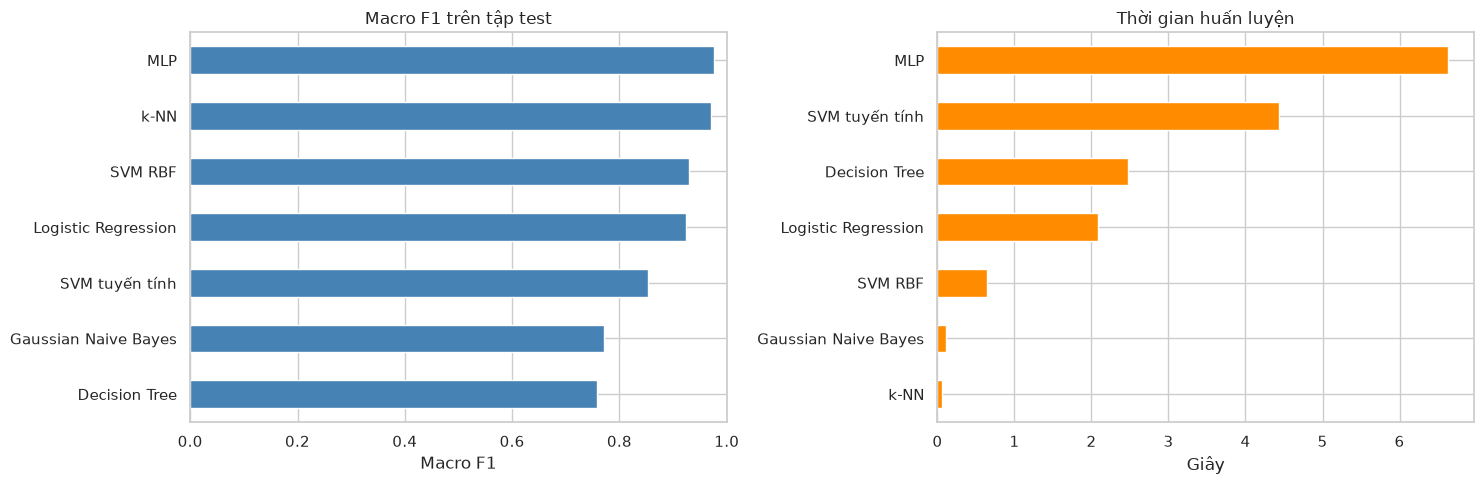

Thời gian suy luận được đo trên toàn bộ tập test (10.000 ảnh):


,Mô hình,Test latency (s),Latency (ms/ảnh)
0,MLP,0.015,0.001
1,k-NN,16.234,1.623
2,SVM RBF,0.362,0.036
3,Logistic Regression,0.009,0.001
4,SVM tuyến tính,0.006,0.001
5,Gaussian Naive Bayes,0.209,0.021
6,Decision Tree,0.003,0.000


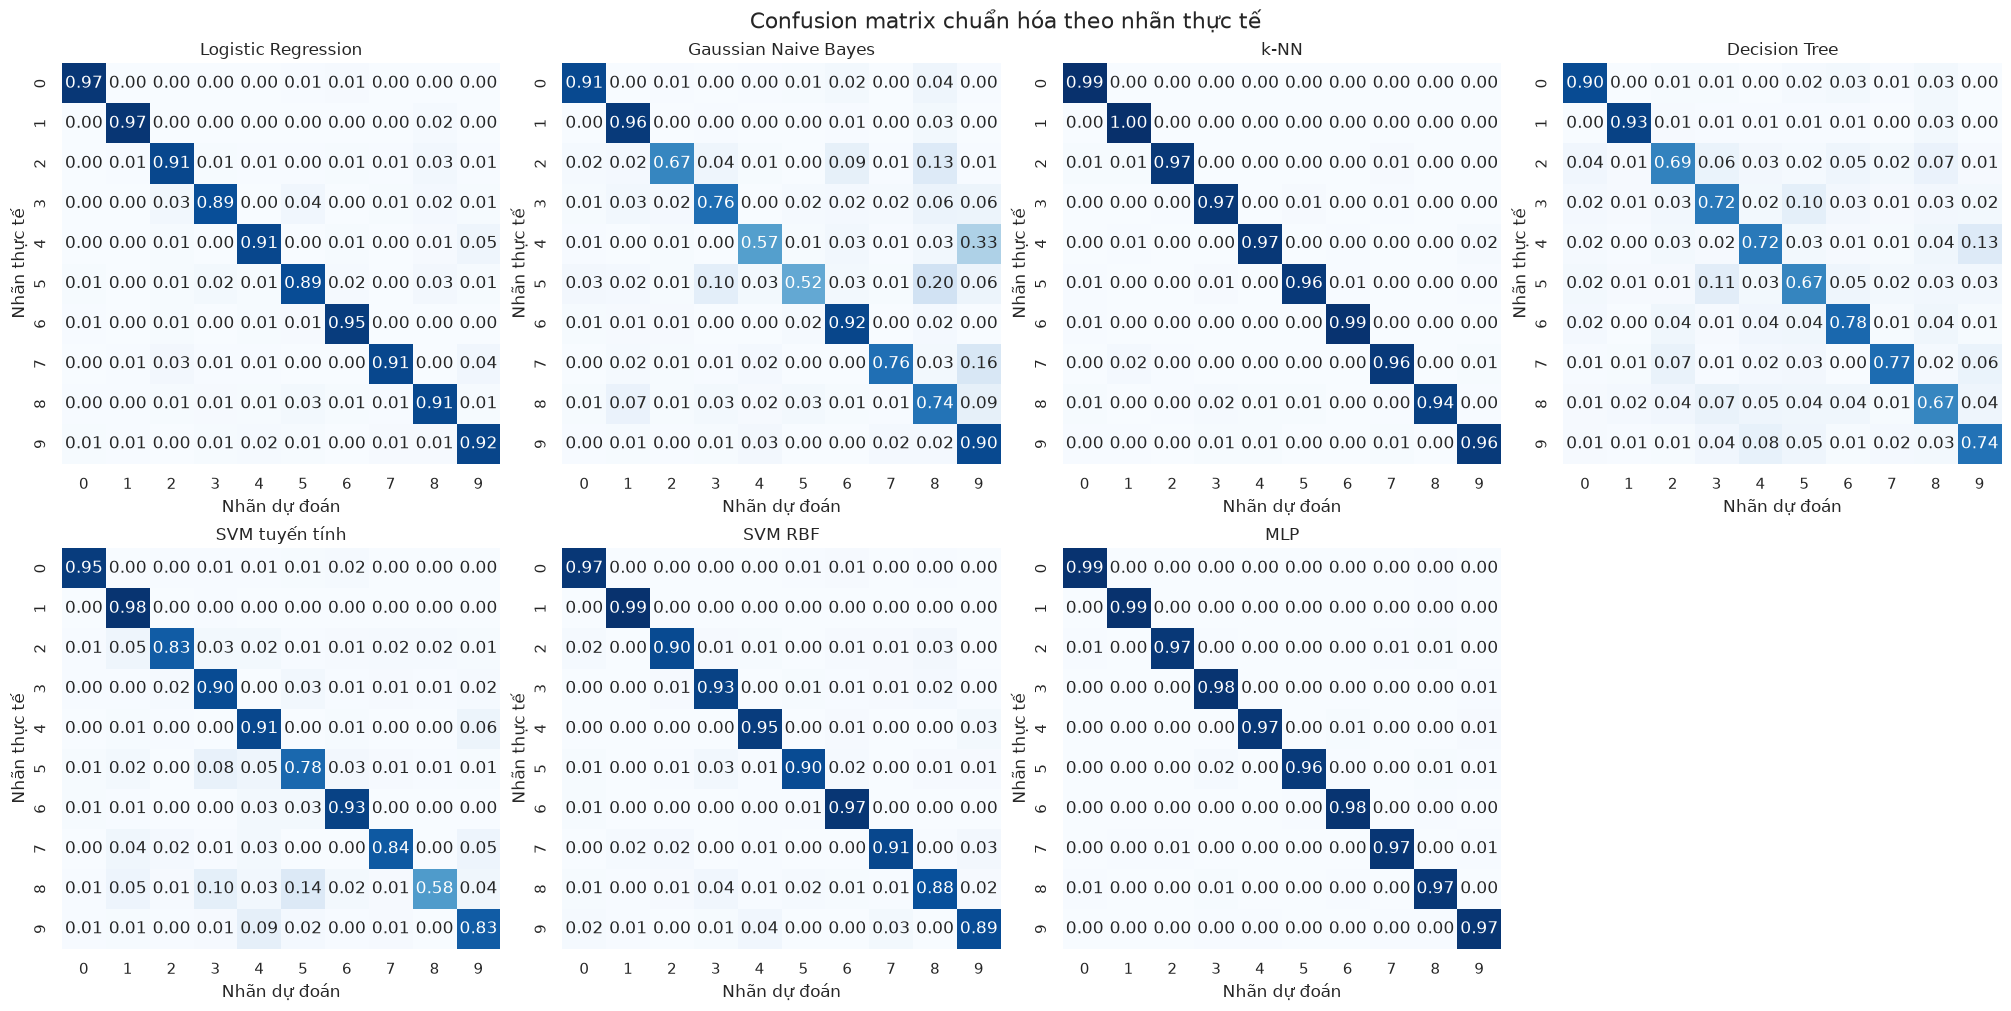

Ba ví dụ phân loại sai đầu tiên của mỗi mô hình; quan sát nét viết và hình dạng gây nhầm lẫn.
Logistic Regression — các cặp nhầm nhiều nhất: 4→9 (49), 3→5 (39), 7→9 (38)
  4→9: số 4 thiếu nét ngang rõ hoặc nét dọc khép vòng nên gần hình số 9.
  3→5: đường cong mở của số 3 bị viết góc cạnh; nét ngang phía trên khiến ảnh gần số 5.
  7→9: nét móc hoặc vòng ở đầu số 7 làm chữ số gần số 9.
Gaussian Naive Bayes — các cặp nhầm nhiều nhất: 4→9 (320), 5→8 (174), 7→9 (162)
  4→9: số 4 thiếu nét ngang rõ hoặc nét dọc khép vòng nên gần hình số 9.
  5→8: nét cong của số 5 khép lại thành vòng, gần hai vòng của số 8.
  7→9: nét móc hoặc vòng ở đầu số 7 làm chữ số gần số 9.
k-NN — các cặp nhầm nhiều nhất: 7→1 (21), 4→9 (19), 8→3 (16)
  7→1: nét ngang hoặc nét xiên ngắn của số 7 yếu khiến ảnh gần nét thẳng của số 1.
  4→9: số 4 thiếu nét ngang rõ hoặc nét dọc khép vòng nên gần hình số 9.
  8→3: một vòng của số 8 bị hở/mờ nên chỉ còn các cung cong giống số 3.
Decision Tree — các cặp nhầm nhiều nhất: 4→9

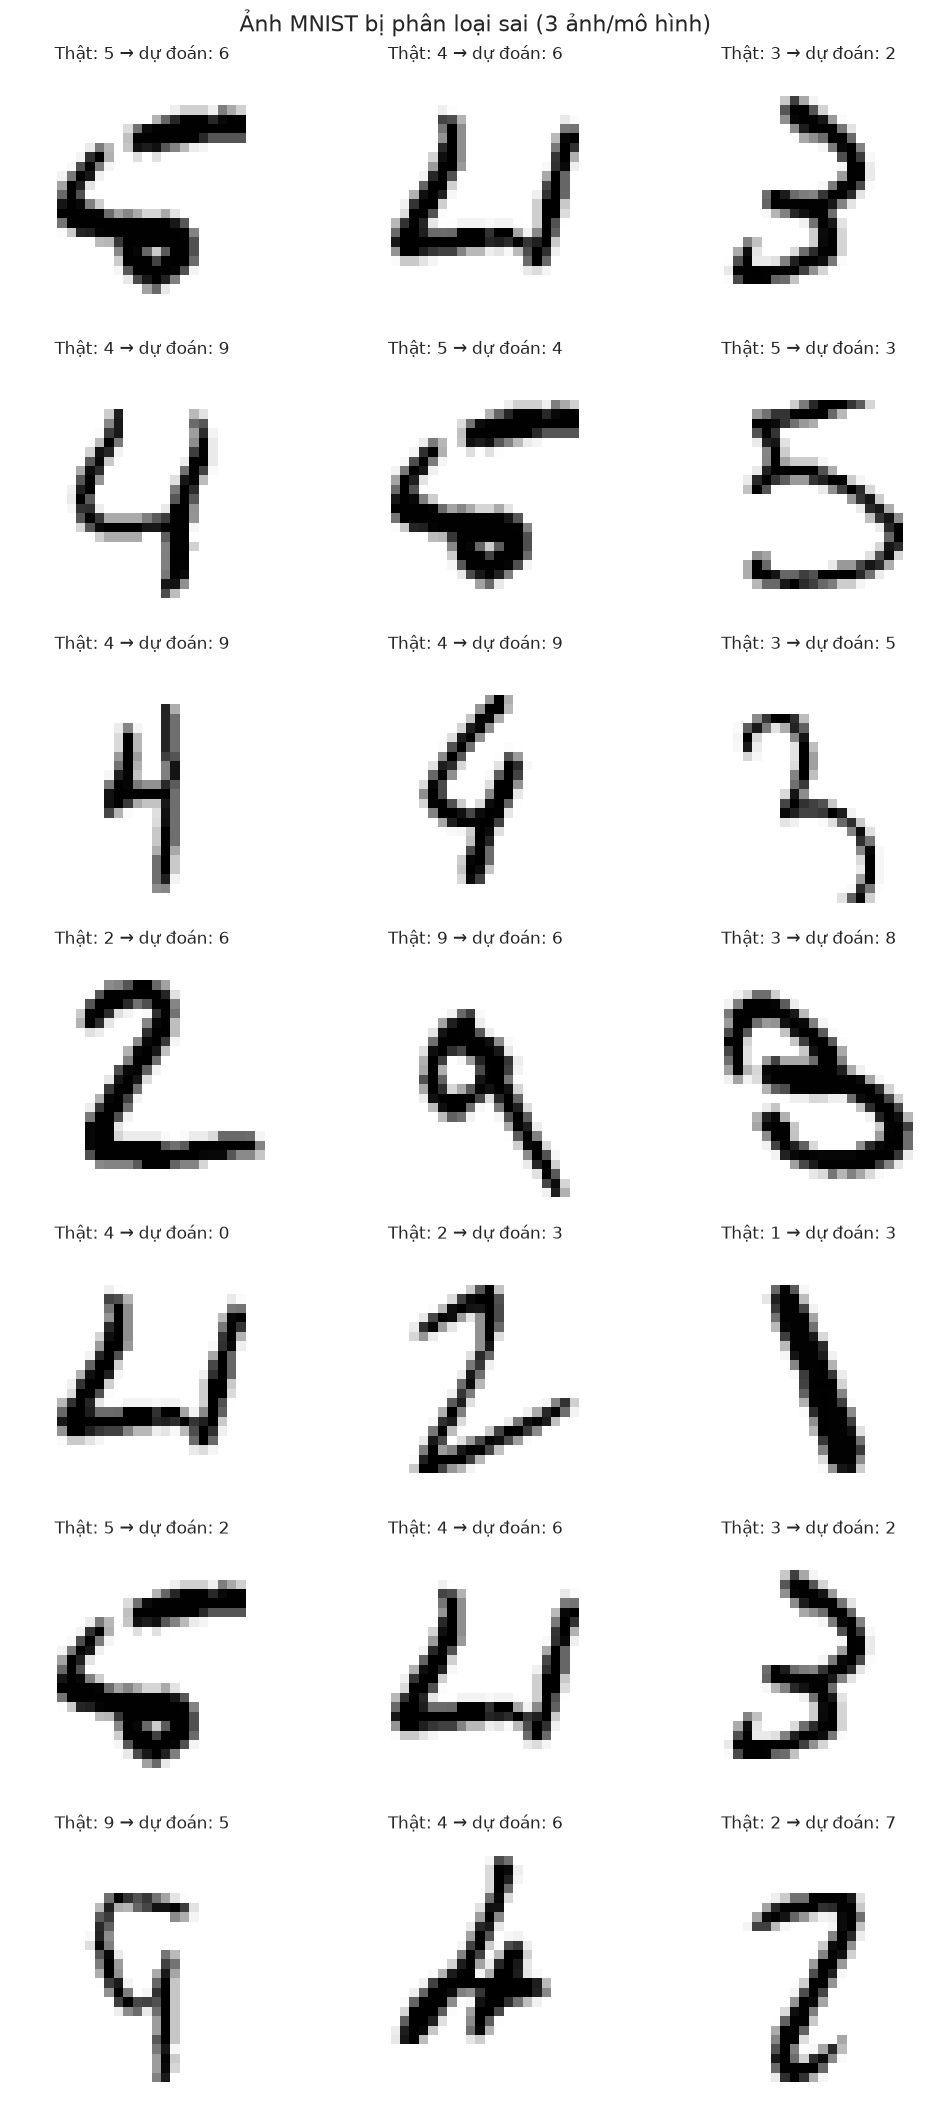

,Mô hình,Nhãn thật,Nhãn dự đoán,Chỉ số test
0,Logistic Regression,5,6,8
1,Logistic Regression,4,6,33
2,Logistic Regression,3,2,63
3,Gaussian Naive Bayes,4,9,4
4,Gaussian Naive Bayes,5,4,8
5,Gaussian Naive Bayes,5,3,15
6,k-NN,4,9,65
7,k-NN,4,9,115
8,k-NN,3,5,195
9,Decision Tree,2,6,1


Mô hình có Macro F1 cao nhất: MLP (0.9757).
Macro F1 trung bình — mô hình tuyến tính: 0.8880; mô hình phi tuyến: 0.9086.
Suy luận nhanh nhất: Decision Tree (0.000 ms/ảnh); chậm nhất: k-NN (1.623 ms/ảnh).
Phân tích hyperparameter: xem Macro F1 validation theo C/gamma, độ sâu cây, k/khoảng cách và learning rate trong bảng tuning; chênh lệch validation-test gợi ý mức độ tổng quát hóa, không nên chỉ chọn theo thời gian huấn luyện.
Phân tích lỗi: so sánh các ảnh thật→dự đoán và confusion matrix. Những nhầm lẫn thường liên quan đến nét nối/đứt, chữ số viết nghiêng, vòng khép chưa kín hoặc các cặp có hình dạng gần nhau; hãy đối chiếu trực tiếp ảnh minh họa của từng mô hình.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
results_df.sort_values("Macro F1").plot(
    x="Mô hình", y="Macro F1", kind="barh", ax=axes[0],
    color="steelblue", legend=False,
)
axes[0].set(title="Macro F1 trên tập test", xlabel="Macro F1", ylabel="")
axes[0].set_xlim(0, 1)
results_df.sort_values("Training time (s)").plot(
    x="Mô hình", y="Training time (s)", kind="barh", ax=axes[1],
    color="darkorange", legend=False,
)
axes[1].set(title="Thời gian huấn luyện", xlabel="Giây", ylabel="")
plt.tight_layout()
plt.show()

print("Thời gian suy luận được đo trên toàn bộ tập test (10.000 ảnh):")
display(results_df[["Mô hình", "Test latency (s)", "Latency (ms/ảnh)"]].round(3))

matrix_rows = 2
matrix_columns = 4
fig, axes = plt.subplots(
    matrix_rows, matrix_columns, figsize=(20, 10), constrained_layout=True
)
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    matrix = confusion_matrix_numpy(y_test, y_pred)
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    sns.heatmap(
        normalized, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
        cbar=False, ax=ax, xticklabels=range(N_CLASSES), yticklabels=range(N_CLASSES),
    )
    ax.set_title(name)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")
for ax in axes.flat[len(predictions):]:
    ax.axis("off")
fig.suptitle("Confusion matrix chuẩn hóa theo nhãn thực tế", fontsize=16)
plt.show()

print("Ba ví dụ phân loại sai đầu tiên của mỗi mô hình; quan sát nét viết và hình dạng gây nhầm lẫn.")
pair_explanations = {
    (4, 9): "số 4 thiếu nét ngang rõ hoặc nét dọc khép vòng nên gần hình số 9.",
    (9, 4): "vòng của số 9 mở/không rõ, còn nét dọc và nét ngang làm ảnh giống số 4.",
    (3, 5): "đường cong mở của số 3 bị viết góc cạnh; nét ngang phía trên khiến ảnh gần số 5.",
    (5, 3): "nét ngang/đầu nét của số 5 mờ, để lại hai cung cong giống số 3.",
    (7, 9): "nét móc hoặc vòng ở đầu số 7 làm chữ số gần số 9.",
    (9, 7): "vòng trên của số 9 bị hở và nét xiên nổi bật nên giống số 7.",
    (7, 1): "nét ngang hoặc nét xiên ngắn của số 7 yếu khiến ảnh gần nét thẳng của số 1.",
    (5, 8): "nét cong của số 5 khép lại thành vòng, gần hai vòng của số 8.",
    (8, 3): "một vòng của số 8 bị hở/mờ nên chỉ còn các cung cong giống số 3.",
    (3, 8): "nét cong của số 3 khép kín hoặc dày lên, tạo cảm giác có hai vòng như số 8.",
    (8, 5): "vòng trên/dưới của số 8 mờ hoặc đứt; phần nét còn lại giống số 5.",
    (2, 8): "nét cong của số 2 khép thành vòng, đặc biệt khi chân ngang ngắn, nên giống số 8.",
    (4, 6): "nét xiên và vòng dưới của số 6 làm mờ cấu trúc góc cạnh của số 4.",
}
fig, axes = plt.subplots(
    len(predictions), 3, figsize=(10, 3 * len(predictions)),
    squeeze=False, constrained_layout=True,
)
error_pair_rows = []
for row, (name, y_pred) in enumerate(predictions.items()):
    error_indices = np.flatnonzero(y_pred != y_test)[:3]
    if len(error_indices) < 3:
        print(f"{name}: chỉ có {len(error_indices)} lỗi để minh họa.")
    for column, ax in enumerate(axes[row]):
        if column >= len(error_indices):
            ax.axis("off")
            continue
        index = error_indices[column]
        ax.imshow(X_test_raw[index], cmap="gray_r")
        ax.set_title(f"Thật: {y_test[index]} → dự đoán: {y_pred[index]}")
        ax.axis("off")
        error_pair_rows.append({
            "Mô hình": name,
            "Nhãn thật": int(y_test[index]),
            "Nhãn dự đoán": int(y_pred[index]),
            "Chỉ số test": int(index),
        })
    matrix = confusion_matrix_numpy(y_test, y_pred)
    np.fill_diagonal(matrix, 0)
    frequent_pairs = np.dstack(np.unravel_index(np.argsort(matrix.ravel())[::-1][:3], matrix.shape))[0]
    pairs = ", ".join(
        f"{actual}→{predicted} ({matrix[actual, predicted]})"
        for actual, predicted in frequent_pairs
        if matrix[actual, predicted] > 0
    )
    print(f"{name} — các cặp nhầm nhiều nhất: {pairs or 'không có lỗi'}")
    for actual, predicted in frequent_pairs:
        if matrix[actual, predicted] > 0:
            explanation = pair_explanations.get(
                (int(actual), int(predicted)),
                "nét đặc trưng bị mờ, đứt hoặc biến dạng khiến hai hình dạng gần nhau.",
            )
            print(f"  {actual}→{predicted}: {explanation}")
fig.suptitle("Ảnh MNIST bị phân loại sai (3 ảnh/mô hình)", fontsize=16)
plt.show()
display(pd.DataFrame(error_pair_rows))

linear_names = ["Logistic Regression", "SVM tuyến tính"]
nonlinear_names = ["k-NN", "Decision Tree", "SVM RBF", "MLP"]
linear_f1 = results_df.set_index("Mô hình").loc[linear_names, "Macro F1"].mean()
nonlinear_f1 = results_df.set_index("Mô hình").loc[nonlinear_names, "Macro F1"].mean()
best_model = results_df.iloc[0]
fastest_inference = results_df.loc[results_df["Latency (ms/ảnh)"].idxmin()]
slowest_inference = results_df.loc[results_df["Latency (ms/ảnh)"].idxmax()]
print(
    f"Mô hình có Macro F1 cao nhất: {best_model['Mô hình']} "
    f"({best_model['Macro F1']:.4f})."
)
print(
    f"Macro F1 trung bình — mô hình tuyến tính: {linear_f1:.4f}; "
    f"mô hình phi tuyến: {nonlinear_f1:.4f}."
)
print(
    f"Suy luận nhanh nhất: {fastest_inference['Mô hình']} "
    f"({fastest_inference['Latency (ms/ảnh)']:.3f} ms/ảnh); "
    f"chậm nhất: {slowest_inference['Mô hình']} "
    f"({slowest_inference['Latency (ms/ảnh)']:.3f} ms/ảnh)."
)
print(
    "Phân tích hyperparameter: xem Macro F1 validation theo C/gamma, độ sâu cây, "
    "k/khoảng cách và learning rate trong bảng tuning; chênh lệch validation-test "
    "gợi ý mức độ tổng quát hóa, không nên chỉ chọn theo thời gian huấn luyện."
)
print(
    "Phân tích lỗi: so sánh các ảnh thật→dự đoán và confusion matrix. Những nhầm lẫn "
    "thường liên quan đến nét nối/đứt, chữ số viết nghiêng, vòng khép chưa kín hoặc "
    "các cặp có hình dạng gần nhau; hãy đối chiếu trực tiếp ảnh minh họa của từng mô hình."
)
